<a href="https://colab.research.google.com/github/VladyslavBiblyi/CSC-349-OL1/blob/main/HW5/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## #1

####I loaded the Heart Disease dataset from the UCI Machine Learning Repository using fetch_ucirepo(id=45). The features and target are returned as Pandas DataFrames. I renamed the outcome column from num to target. I also combined featured and target variables together.

In [1]:
!pip install ucimlrepo -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, roc_auc_score, accuracy_score)

heart_disease = fetch_ucirepo(id=45)

heart = pd.concat([
    heart_disease.data.features,
    heart_disease.data.targets
], axis=1)

heart = heart.rename(columns={"num": "target"})

## #2

#### I used head() to view sample records, info() to check column types and non-na counts, and describe() to summarize the features.

In [2]:
display(heart.head())

heart.info()

display(heart.describe(include="all"))

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


## #3

#### I counted missing values and standard placeholders such as ?. The UCI importer already converts question-mark placeholders to NaN. I used median for numerical features because it is less sensitive to extremes. For categorical features, I used the most frequent category. I also converted the outcome to binary values, 0 for no disease and 1 for disease. The missing values remained in the original df, but the pipeline will fill them using SimpleImputer during model training.

In [10]:
print("Missing values:")
print(heart.isnull().sum())

print("\n?:")
print(heart.eq("?").sum())

heart["target"] = (heart["target"] > 0).astype(int)

num = SimpleImputer(strategy="median")
cat = SimpleImputer(strategy="most_frequent")

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

?:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


## #4

####I separated num and cat variables. The num pipeline fills missing values with the median and applies StandardScaler. The cat pipeline fills missing values with the most frequent category and applies OneHotEncoder. I combined both pipelines using ColumnTransformer. Then I separated predictors and outcome. I used a 80/20 split.

In [4]:
num = ["age", "trestbps", "chol", "thalach", "oldpeak"]

cat = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num),
    ("cat", cat_pipeline, cat)])

X = heart.drop("target", axis=1)
y = heart["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## #5

####I created a pipeline containing preprocessing and an SVC with RBF kernel and probability=True. I generated test predictions and probability estimates for disease(=1). Performed classification report, confusion matrix, ROC curve, and ROC-AUC.

              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

SVC ROC AUC: 0.9642857142857143


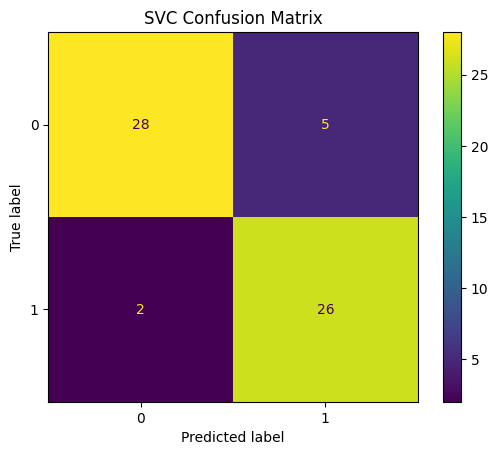

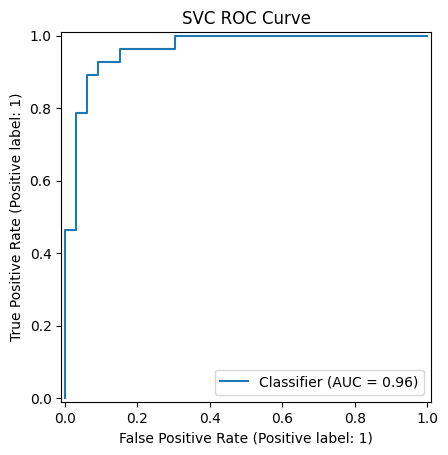

In [9]:
svm_clf = Pipeline([
    ("preprocessor", preprocessor),
    ("svc", SVC(kernel="rbf", probability=True, random_state=42))])

svm_clf.fit(X_train, y_train)

svm_pred = svm_clf.predict(X_test)
svm_prob = svm_clf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, svm_pred))
print("SVC ROC AUC:", roc_auc_score(y_test, svm_prob))

ConfusionMatrixDisplay.from_predictions(y_test, svm_pred)
plt.title("SVC Confusion Matrix")
plt.show()

RocCurveDisplay.from_predictions(y_test, svm_prob)
plt.title("SVC ROC Curve")
plt.show()

## #6

####I created another pipeline with preprocessing and a Decision Tree Classifier. I evaluated the tree using the same test set and metrics as the SVC: a classification report, confusion matrix, ROC curve, and ROC-AUC score.

              precision    recall  f1-score   support

           0       0.83      0.73      0.77        33
           1       0.72      0.82      0.77        28

    accuracy                           0.77        61
   macro avg       0.77      0.77      0.77        61
weighted avg       0.78      0.77      0.77        61

DT ROC-AUC: 0.8728354978354979


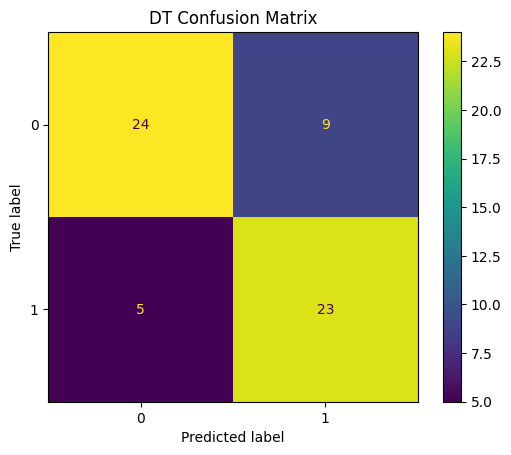

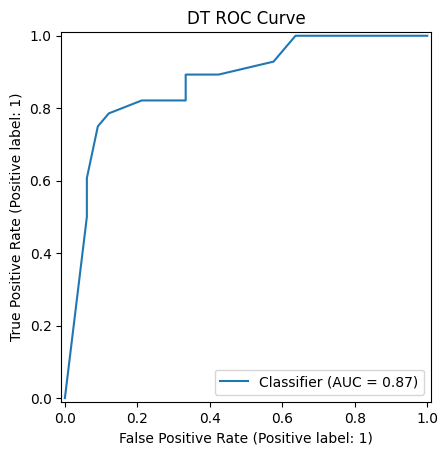

In [6]:
dt_clf = Pipeline([
    ("preprocessor", preprocessor),
    ("tree", DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42))])

dt_clf.fit(X_train, y_train)

dt_pred = dt_clf.predict(X_test)
dt_prob = dt_clf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, dt_pred))
print("DT ROC-AUC:", roc_auc_score(y_test, dt_prob))

ConfusionMatrixDisplay.from_predictions(y_test, dt_pred)
plt.title("DT Confusion Matrix")
plt.show()

RocCurveDisplay.from_predictions(y_test, dt_prob)
plt.title("DT ROC Curve")
plt.show()

## #7

#### I used GridSearchCV to compare combinations of C and gamma. The search uses fivefold cross validation on training and picks the combination with the highest mean validation ROC-AUC. Preprocessing is fitted within each fold. I displayed the selected parameters and their mean cross validation score.

In [7]:
params = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.01, 0.1]
}

grid_search_cv = GridSearchCV(svm_clf, params, cv=5, scoring="roc_auc")

grid_search_cv.fit(X_train, y_train)

print("Best parameters:", grid_search_cv.best_params_)
print("Best CV ROC-AUC:", grid_search_cv.best_score_)

Best parameters: {'svc__C': 1, 'svc__gamma': 0.01}
Best CV ROC-AUC: 0.8882830535004448


## #8

#### I extracted the trained tree and the feature names from preprocessing. I visualised the tree using plot_tree. I also displayed the largest feature importances. These values measure contributions to impurity reduction in this particular tree. They do not establish causation or show the direction of a relationship.

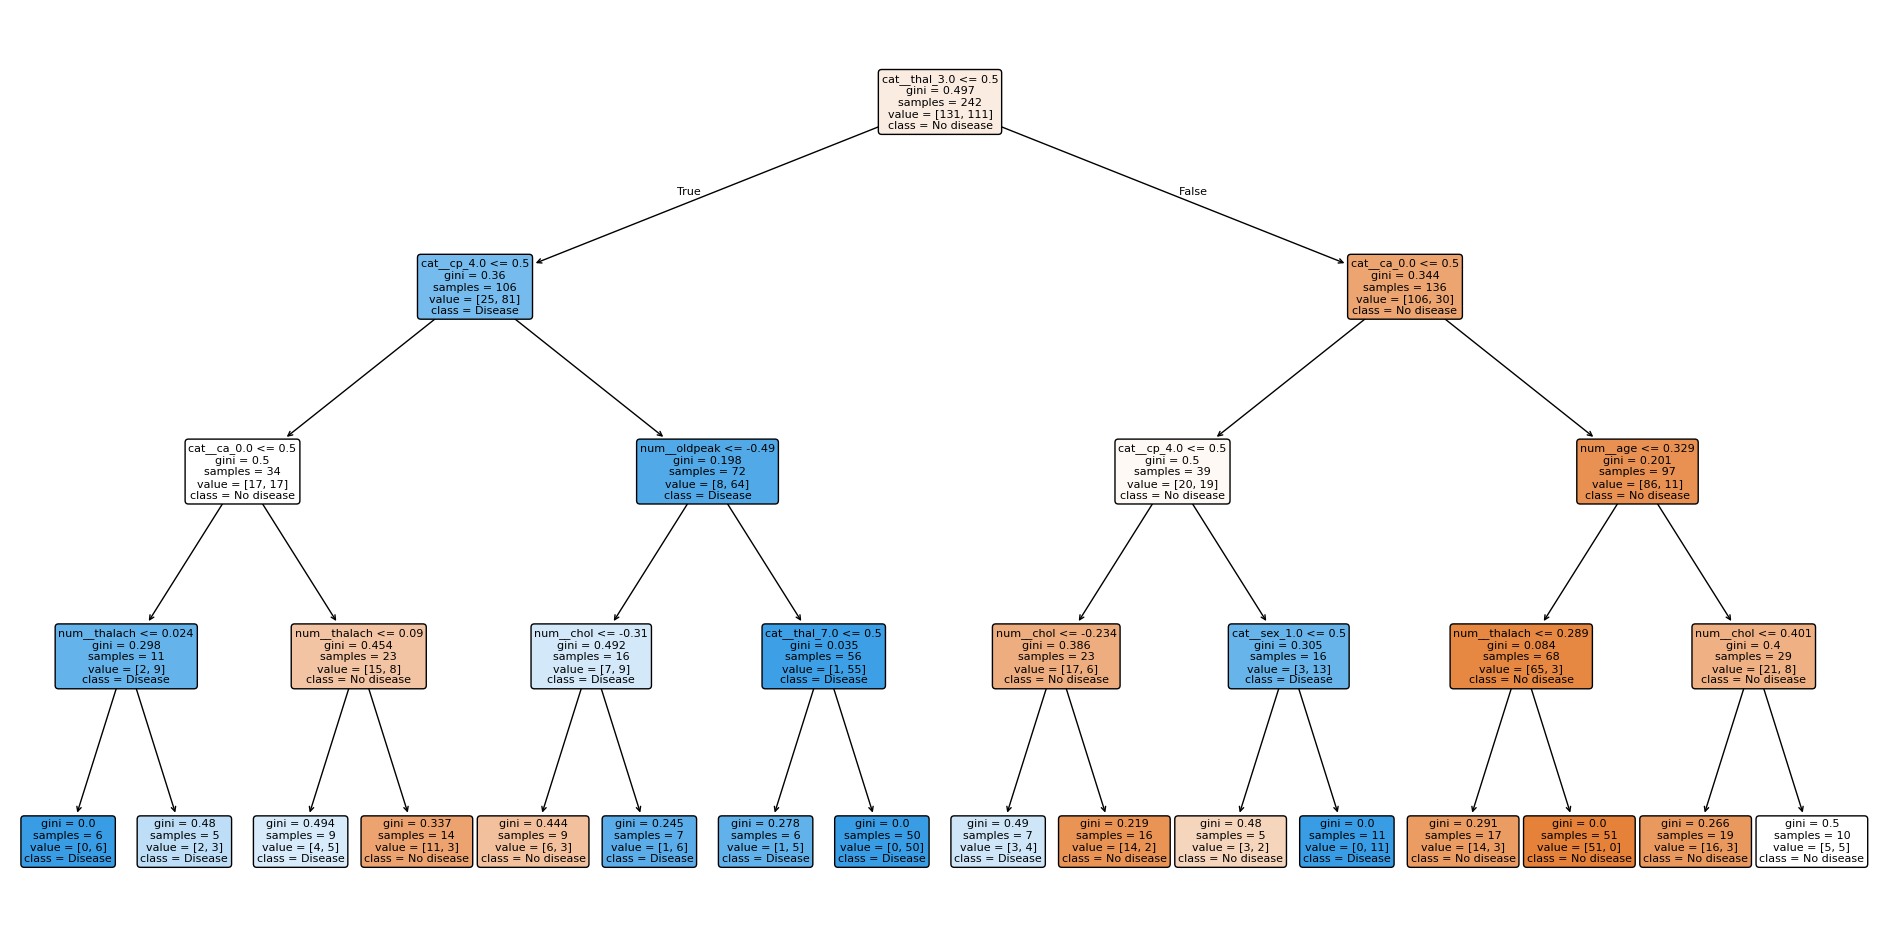

,0
cat__thal_3.0,0.457686
cat__cp_4.0,0.165488
cat__ca_0.0,0.143865
num__chol,0.073270
num__oldpeak,0.056987
num__thalach,0.038263
cat__sex_1.0,0.032180
num__age,0.028392
cat__thal_7.0,0.003870
cat__cp_1.0,0.000000


In [8]:
tree = dt_clf.named_steps["tree"]

feature_names = (dt_clf.named_steps["preprocessor"].get_feature_names_out())

plt.figure(figsize=(24, 12))

plot_tree(tree, feature_names=feature_names, class_names=["No disease", "Disease"],
    filled=True, rounded=True, fontsize=8)

plt.show()

importances = pd.Series(tree.feature_importances_, index=feature_names)

display(importances.sort_values(ascending=False).head(10))